# Nashville Housing Data Cleaning

**Goal:** turn a messy export of Nashville (Davidson County) property sales from 2013-2016 into a trustworthy, analysis-ready table, and document every decision along the way.

**How this notebook is organised**

1. Load and profile the raw data
2. Audit: what is wrong with it?
3. Clean, one step at a time (each step shows the problem, runs the fix from [`src/clean_nashville.py`](../src/clean_nashville.py), then shows the result)
4. Validate the cleaned data with assertions
5. Before / after comparison and a quick sanity analysis
6. Save outputs

Tools: Python, pandas, NumPy, matplotlib, seaborn.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, "../src")
import clean_nashville as cn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

IMAGES = Path("../images")
BLUE, ORANGE, GREY = "#2b6cb0", "#dd6b20", "#a0aec0"
log = cn.CleaningLog()

## 1. Load and profile the raw data

In [2]:
raw = cn.load_raw()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head(3).T

56,636 rows x 31 columns

,0,1,2
Unnamed: 0.1,0,1,2
Unnamed: 0,0,1,2
Parcel ID,105 03 0D 008.00,105 11 0 080.00,118 03 0 130.00
Land Use,RESIDENTIAL CONDO,SINGLE FAMILY,SINGLE FAMILY
Property Address,1208 3RD AVE S,1802 STEWART PL,2761 ROSEDALE PL
Suite/ Condo #,8,NaN,NaN
Property City,NASHVILLE,NASHVILLE,NASHVILLE
Sale Date,2013-01-24,2013-01-11,2013-01-18
Sale Price,132000,191500,202000
Legal Reference,20130128-0008725,20130118-0006337,20130124-0008033


In [3]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
})
profile

,dtype,non_null,missing_%,unique
Unnamed: 0.1,int64,56636,0.0,56636
Unnamed: 0,int64,56636,0.0,56636
Parcel ID,str,56636,0.0,48697
Land Use,str,56636,0.0,39
Property Address,str,56477,0.3,45068
Suite/ Condo #,str,6109,89.2,1952
Property City,str,56477,0.3,14
Sale Date,str,56636,0.0,1117
Sale Price,int64,56636,0.0,8085
Legal Reference,str,56636,0.0,52898


## 2. Audit: what is wrong with this data?

Before changing anything I want a list of concrete problems. Findings from profiling:

| # | Problem | Evidence |
|---|---|---|
| 1 | Two identical exported index columns and a Windows file-path column (`image`) | `Unnamed: 0`, `Unnamed: 0.1`, `image` |
| 2 | Column names contain spaces, odd spacing (`Suite/ Condo   #`) | header row |
| 3 | Repeated internal whitespace in addresses and owner names | `'1208  3RD AVE S'` |
| 4 | Same land-use category spelled several ways, plus typos | `VACANT RES LAND` vs `VACANT RESIDENTIAL LAND`, `RESIENTIAL`, `RESTURANT` |
| 5 | Placeholder value `UNKNOWN` as a city; Yes/No stored as text | `Property City`, `Sold As Vacant` |
| 6 | Integers stored as floats; dates stored as text | `Year Built = 1941.0`, `Sale Date` |
| 7 | Malformed legal references | `'20130682- 006678'` |
| 8 | The same sale recorded twice | same parcel + date + price |
| 9 | Impossible values | finished area `0`, single-family with `0` bedrooms |
| 10 | Nominal-price sales and multi-parcel bundle prices | `$50`, `$100`; one `$54,278,060` price repeated on 7 rows |
| 11 | **Over half the rows have no assessor data at all** | see below |

Problem 11 deserves a closer look because it determines how much of the data is usable.

In [4]:
assessor_cols = ["Address", "City", "State", "Acreage", "Tax District", "Neighborhood",
                 "Land Value", "Building Value", "Total Value"]
all_missing = raw[assessor_cols].isna().all(axis=1)
print(f"Rows with EVERY assessor field missing: {all_missing.sum():,} ({all_missing.mean():.1%})")

# Could these be recovered from another sale of the same parcel?
details = raw.loc[~all_missing, "Parcel ID"].unique()
recoverable = raw.loc[all_missing, "Parcel ID"].isin(details).sum()
print(f"...of which recoverable from another sale of the same parcel: {recoverable}")

Rows with EVERY assessor field missing: 30,619 (54.1%)
...of which recoverable from another sale of the same parcel: 0

**None of the empty rows can be back-filled from other sales of the same parcel**, which is the usual trick for this dataset. So the missing values are not random gaps to impute. Let me see whether they follow a pattern.

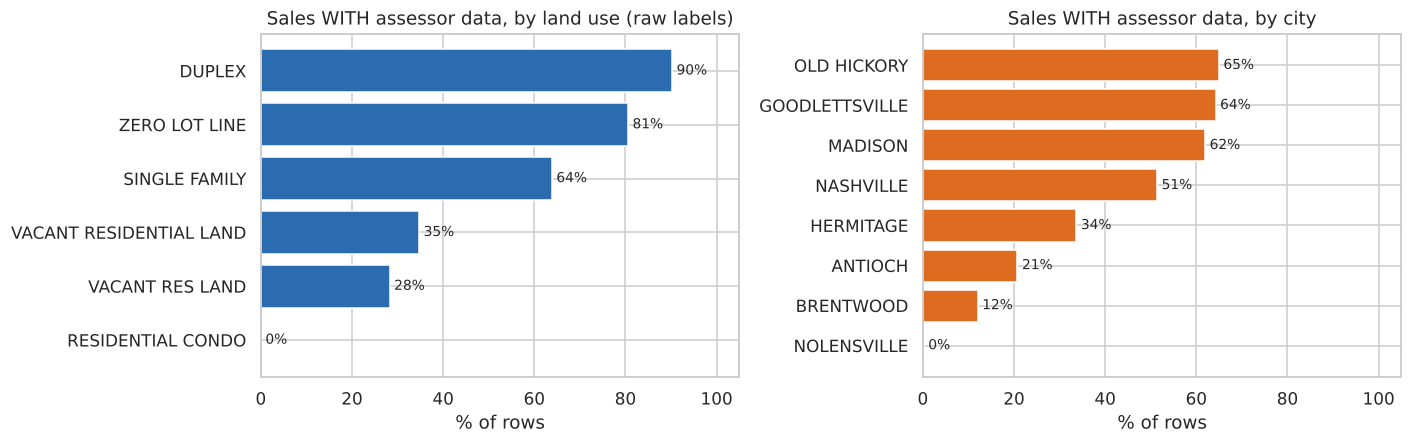

In [5]:
r = raw.copy()
r["has_assessor_data"] = ~all_missing
r["Land Use"] = r["Land Use"].str.strip()

by_use = (r.groupby("Land Use")["has_assessor_data"].agg(["mean", "size"])
            .query("size >= 400").sort_values("mean"))
by_city = (r.groupby("Property City")["has_assessor_data"].agg(["mean", "size"])
             .query("size >= 400").sort_values("mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].barh(by_use.index, by_use["mean"] * 100, color=BLUE)
axes[0].set_title("Sales WITH assessor data, by land use (raw labels)")
axes[1].barh(by_city.index, by_city["mean"] * 100, color=ORANGE)
axes[1].set_title("Sales WITH assessor data, by city")
for ax, d in zip(axes, [by_use, by_city]):
    ax.set_xlabel("% of rows"); ax.set_xlim(0, 105)
    for y, v in enumerate(d["mean"] * 100):
        ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(IMAGES / "01_assessor_data_coverage.png", dpi=150, bbox_inches="tight")
plt.show()

**The missingness is structural, not random.** Every residential condo sale lacks assessor details, and several cities (e.g. Brentwood, Antioch, Nolensville) are mostly missing too.

Decision: **keep these rows** (they still contain valid sale dates, prices and addresses) but add a `has_assessor_data` flag so any analysis that needs square footage, year built, etc. can filter explicitly rather than silently losing half the data or imputing values that would be fabricated.

## 3. Cleaning, step by step

### Step 1: Drop junk columns, standardise column names

In [6]:
print("BEFORE:", list(raw.columns[:6]), "...")
df = cn.tidy_columns(raw, log)
print("AFTER: ", list(df.columns))

BEFORE: ['Unnamed: 0.1', 'Unnamed: 0', 'Parcel ID', 'Land Use', 'Property Address', 'Suite/ Condo   #'] ...
AFTER:  ['parcel_id', 'land_use', 'property_address', 'suite_condo_no', 'property_city', 'sale_date', 'sale_price', 'legal_reference', 'sold_as_vacant', 'multiple_parcels_in_sale', 'owner_name', 'assessor_address', 'assessor_city', 'state', 'acreage', 'tax_district', 'neighborhood', 'land_value', 'building_value', 'total_value', 'finished_area', 'foundation_type', 'year_built', 'exterior_wall', 'grade', 'bedrooms', 'full_bath', 'half_bath']

### Step 2: Whitespace and casing in text fields

In [7]:
sample = raw.loc[[1, 2, 7, 9], ["Property Address", "Owner Name"]]
df = cn.clean_text_fields(df, log)
print("BEFORE"); display(sample)
print("AFTER");  display(df.loc[sample.index, ["property_address", "owner_name"]])

BEFORE
AFTER

,Property Address,Owner Name
1,1802 STEWART PL,"STINSON, LAURA M."
2,2761 ROSEDALE PL,"NUNES, JARED R."
7,501 MORTON AVE,"MICKLER, PATRICK L. & LOIS J. & ARNETT, RYAN D."
9,113 NEESE DR,"SONA LAND CO, LLC"


,property_address,owner_name
1,1802 STEWART PL,"STINSON, LAURA M."
2,2761 ROSEDALE PL,"NUNES, JARED R."
7,501 MORTON AVE,"MICKLER, PATRICK L. & LOIS J. & ARNETT, RYAN D."
9,113 NEESE DR,"SONA LAND CO, LLC"


### Step 3: Standardise `Land Use`

The same category appears under different labels. I merge the unambiguous variants. The bare label `CONDO` is **not** merged into `RESIDENTIAL CONDO`: its price profile is very different, so it appears to be a different population rather than a typo.

In [8]:
before_counts = df["land_use"].str.strip().value_counts()
df = cn.standardise_land_use(df, log)
after_counts = df["land_use"].value_counts()

variants = ["VACANT RES LAND", "VACANT RESIDENTIAL LAND", "VACANT RESIENTIAL LAND",
            "RESTURANT/CAFETERIA", "RESTAURANT/CAFETERIA"]
pd.DataFrame({
    "before": before_counts.reindex(variants),
    "after": after_counts.reindex(variants),
}).fillna(0).astype(int)

,before,after
land_use,,
VACANT RES LAND,1575,0
VACANT RESIDENTIAL LAND,3586,5164
VACANT RESIENTIAL LAND,3,0
RESTURANT/CAFETERIA,2,0
RESTAURANT/CAFETERIA,0,2


In [9]:
print(f"Distinct land-use labels: {before_counts.size} -> {after_counts.size}")
df["land_use_group"].value_counts()

Distinct land-use labels: 39 -> 37

,count
land_use_group,
Residential,51052
Vacant / land,5219
Commercial / other,365


### Step 4: Categoricals, placeholders and city back-fill

In [10]:
print("Property City before:", raw["Property City"].isna().sum(), "missing,",
      (raw["Property City"] == "UNKNOWN").sum(), "'UNKNOWN'")
df = cn.standardise_categoricals(df, log)
print("Property City after: ", df["property_city"].isna().sum(), "missing")
df[["sold_as_vacant", "multiple_parcels_in_sale"]].dtypes

Property City before: 159 missing, 1 'UNKNOWN'
Property City after:  158 missing

,0
sold_as_vacant,boolean
multiple_parcels_in_sale,boolean


### Step 5: Correct data types

In [11]:
before_types = df.dtypes.astype(str)
df = cn.parse_types(df, log)
changed = pd.DataFrame({"before": before_types, "after": df.dtypes.astype(str)})
changed[changed["before"] != changed["after"]]

,before,after
bedrooms,float64,Int64
full_bath,float64,Int64
half_bath,float64,Int64
neighborhood,float64,Int64
sale_date,str,datetime64[us]
sale_month,NaN,int64
sale_year,NaN,int64
year_built,float64,Int64


### Step 6: Validate legal references

A valid reference looks like `YYYYMMDD-NNNNNNN`. Malformed ones cannot be repaired reliably (digits are missing or shifted), so I flag them instead of guessing.

In [12]:
df = cn.validate_legal_reference(df, log)
df.loc[~df["legal_ref_valid"], ["parcel_id", "sale_date", "legal_reference"]].head(8)

,parcel_id,sale_date,legal_reference
2863,104 10 0R 007.00,2013-05-17,2013520-0050586
4019,103 13 0 046.00,2013-06-25,20130682- 006678
4345,141 15 0D 203.00,2013-06-28,20130705- 006994
4743,083 14 0 153.00,2013-06-07,20130610-00588852
6404,161 04 0 019.00,2013-08-16,2013 082- 008743
6602,104 01 0 236.00,2013-08-22,20113082- 009096
15004,147 06 0 093.00,2014-05-23,20140527-00 4495
16335,103 03 0 205.00,2014-06-23,20140625- 005531


### Step 7: Remove duplicate sales

Several sales appear twice with an identical parcel, date, price and owner, but a **different (usually malformed) legal reference**. These are the same transaction entered twice. I keep the row whose legal reference is valid.

In [13]:
key = ["parcel_id", "sale_date", "sale_price"]
dups = df[df.duplicated(key, keep=False)].sort_values(key)
dups[["parcel_id", "property_address", "sale_date", "sale_price", "legal_reference", "legal_ref_valid"]].head(6)

,parcel_id,property_address,sale_date,sale_price,legal_reference,legal_ref_valid
36531,034 03 0 059.00,2117 PAULA DR,2015-08-13,245000,20150819-0083759,True
36532,034 03 0 059.00,2117 PAULA DR,2015-08-13,245000,25015081- 008375,False
48760,034 05 0 041.00,512 MONICA AVE,2016-05-13,172500,20160520-0050464,True
48761,034 05 0 041.00,512 MONICA AVE,2016-05-13,172500,20160652-0005046,True
26242,042 03 0 023.00,918 WOODS LAKE DR,2015-01-28,164900,20150130-0008884,True
26243,042 03 0 023.00,918 WOODS LAKE DR,2015-01-28,164900,20150130-0008883,True


In [14]:
df = cn.drop_duplicate_sales(df, log)
print(f"Remaining rows: {len(df):,}   Remaining duplicates on key: {df.duplicated(key).sum()}")
print(f"Malformed legal references remaining: {(~df['legal_ref_valid']).sum()}")

Remaining rows: 56,468   Remaining duplicates on key: 0
Malformed legal references remaining: 27

### Step 8: Impossible values and Grade codes

In [15]:
print("Finished area == 0:", (df["finished_area"] == 0).sum())
print("Single-family with 0 bedrooms:", ((df["bedrooms"] == 0) & (df["land_use"] == "SINGLE FAMILY")).sum())
print("Grade values before:", df["grade"].value_counts().to_dict())
df = cn.clean_property_attributes(df, log)
print("Grade values after: ", df["grade"].value_counts().to_dict())

Finished area == 0: 2
Single-family with 0 bedrooms: 4
Grade values before: {'C   ': 17210, 'B   ': 3692, 'D   ': 1973, 'A   ': 597, 'X   ': 523, 'E   ': 60, 'TCC ': 20, 'AAC ': 3, 'AAB ': 3, 'IDC ': 3, 'OFC ': 2, 'TAC ': 1, 'SSC ': 1, 'SRC ': 1, 'SRD ': 1, 'TFC ': 1, 'TCB ': 1, 'OMB ': 1, 'OFB ': 1, 'TCD ': 1}
Grade values after:  {'C': 17210, 'B': 3692, 'D': 1973, 'A': 597, 'X': 523, 'E': 60, 'OTHER': 40}

### Step 9: Flag rows that need care instead of deleting them

Outliers here are mostly **real transactions with different meaning**, not errors:

* **`nominal_price`**: sales under $1,000 (e.g. $50) are almost certainly non-market transfers.
* **`price_is_bundle_total`**: when several parcels sell together, the *total* price is repeated on each parcel's row, so summing or averaging prices double-counts.
* **`sold_as_vacant_mismatch`**: the vacant-sale flag disagrees with the land-use label.
* **`built_after_sale`**: the recorded build year is later than the sale year.
* **`price_comparable`**: convenience flag = not nominal and not a bundle total.

In [16]:
df = cn.add_quality_flags(df, log)
flags = ["has_assessor_data", "nominal_price", "price_is_bundle_total",
         "sold_as_vacant_mismatch", "built_after_sale", "price_comparable"]
pd.DataFrame({"rows": df[flags].sum(), "share_%": (df[flags].mean() * 100).round(1)})

,rows,share_%
has_assessor_data,25944,45.9
nominal_price,7,0.0
price_is_bundle_total,4678,8.3
sold_as_vacant_mismatch,1982,3.5
built_after_sale,778,1.4
price_comparable,51784,91.7


In [17]:
# The most extreme price in the file is one bundle sale repeated across parcels
df.loc[df["sale_price"] == df["sale_price"].max(),
       ["parcel_id", "property_address", "sale_price", "multiple_parcels_in_sale"]].head(3)

,parcel_id,property_address,sale_price,multiple_parcels_in_sale
25631,093 13 0B 108.00,320 11TH AVE S,54278060,True
25632,093 13 0B 134.00,320 11TH AVE S,54278060,True
25633,093 13 0B 322.00,320 11TH AVE S,54278060,True


### Step 10: Derived features

In [18]:
df = cn.add_derived_features(df, log)
df[["sale_price", "finished_area", "price_per_sqft", "year_built", "age_at_sale"]].describe().round(1)

,sale_price,finished_area,price_per_sqft,year_built,age_at_sale
count,56468.0,24094.0,23002.0,24095.0,23317.0
mean,327580.6,1927.7,135.4,1963.7,52.6
std,930063.2,1688.9,71.2,26.5,25.2
min,50.0,450.0,0.5,1799.0,0.0
25%,135000.0,1239.2,84.5,1948.0,36.0
50%,205837.5,1632.0,119.8,1960.0,55.0
75%,329000.0,2212.9,177.0,1983.0,67.0
max,54278060.0,197988.0,2453.3,2017.0,216.0


## 4. Validation

Assertions make the "clean" claim testable.

In [19]:
df = df.reset_index(drop=True)

checks = {
    "no duplicate parcel/date/price": not df.duplicated(["parcel_id", "sale_date", "sale_price"]).any(),
    "no leading/trailing/double spaces in property_address":
        not df["property_address"].dropna().str.contains(r"^\s|\s$|\s{2}", regex=True).any(),
    "sale_date is datetime": str(df["sale_date"].dtype).startswith("datetime64"),
    "sale dates within 2013-01-01..2016-12-31": df["sale_date"].between("2013-01-01", "2016-12-31").all(),
    "land use labels are unique after merge": "VACANT RES LAND" not in set(df["land_use"]),
    "no 'UNKNOWN' cities": not (df["property_city"] == "UNKNOWN").any(),
    "no zero finished areas": not (df["finished_area"] == 0).any(),
    "grade only A-E, X, OTHER or missing": df["grade"].dropna().isin(cn.VALID_GRADES | {"OTHER"}).all(),
    "has_assessor_data rows have a total_value": df.loc[df["has_assessor_data"], "total_value"].notna().all(),
    "sale_price strictly positive": (df["sale_price"] > 0).all(),
}
result = pd.Series(checks, name="passed")
assert result.all(), result[~result]
result

,passed
no duplicate parcel/date/price,True
no leading/trailing/double spaces in property_address,True
sale_date is datetime,True
sale dates within 2013-01-01..2016-12-31,True
land use labels are unique after merge,True
no 'UNKNOWN' cities,True
no zero finished areas,True
"grade only A-E, X, OTHER or missing",True
has_assessor_data rows have a total_value,True
sale_price strictly positive,True


## 5. Before vs after

In [20]:
summary = pd.DataFrame({
    "raw": [len(raw), raw.shape[1], int(raw.isna().sum().sum()), int(raw.duplicated(["Parcel ID", "Sale Date", "Sale Price"]).sum()),
            raw["Land Use"].nunique(), round(raw.memory_usage(deep=True).sum() / 1e6, 1)],
    "clean": [len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated(["parcel_id", "sale_date", "sale_price"]).sum()),
              df["land_use"].nunique(), round(df.memory_usage(deep=True).sum() / 1e6, 1)],
}, index=["rows", "columns", "missing cells", "duplicate sales", "distinct land-use labels", "memory (MB)"])
summary

,raw,clean
rows,56636.0,56468.0
columns,31.0,38.0
missing cells,648773.0,621153.0
duplicate sales,168.0,0.0
distinct land-use labels,39.0,37.0
memory (MB),57.9,48.9


The column count goes **up** because the flags and derived features add information; the junk columns were removed. Missing cells mostly remain, on purpose: they are structural (see section 2), not errors.

### Does the cleaning change the analysis? A quick sanity check

Raw sale prices span $50 to $54 million. The flags let us separate bundle totals and nominal transfers from ordinary market sales without deleting them. The mean is pulled up by flagged rows; the median barely moves.

Mean price,   all single-family & condo sales: $325,920
Mean price,   comparable sales only:           $269,925
Median price, all single-family & condo sales: $211,000
Median price, comparable sales only:           $210,000

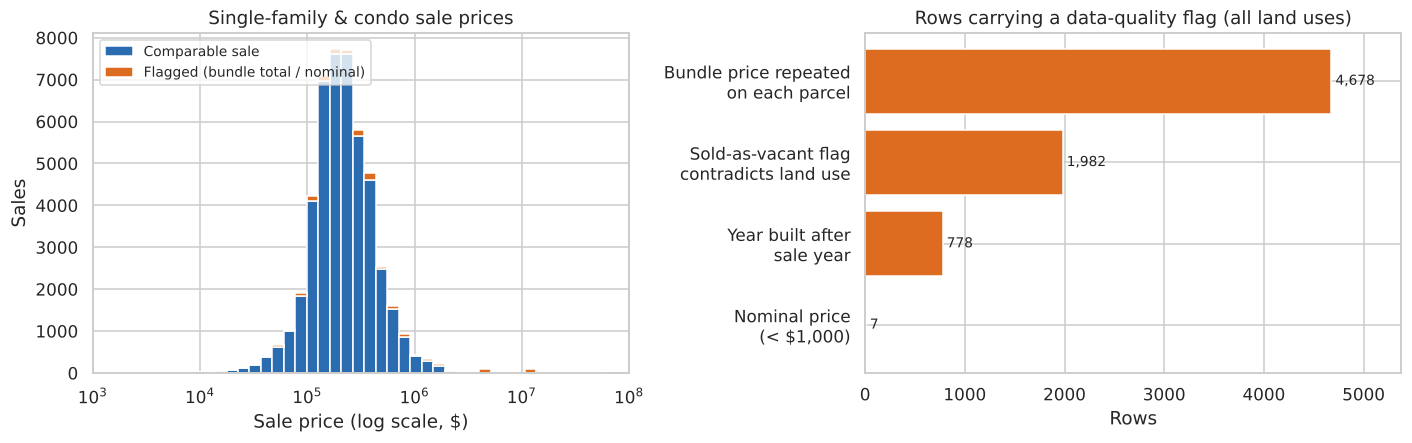

In [21]:
sfc = df[df["land_use"].isin(["SINGLE FAMILY", "RESIDENTIAL CONDO"])]
comp = sfc[sfc["price_comparable"]]
flagged = sfc[~sfc["price_comparable"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.logspace(2, np.log10(6e7), 55)
axes[0].hist([comp["sale_price"], flagged["sale_price"]], bins=bins, stacked=True,
             color=[BLUE, ORANGE], label=["Comparable sale", "Flagged (bundle total / nominal)"])
axes[0].set_xscale("log")
axes[0].set_title("Single-family & condo sale prices")
axes[0].set_xlabel("Sale price (log scale, $)"); axes[0].set_ylabel("Sales"); axes[0].set_xlim(1e3, 1e8); axes[0].legend(loc="upper left", fontsize=9)

counts = pd.Series({
    "Bundle price repeated\non each parcel": int(df["price_is_bundle_total"].sum()),
    "Sold-as-vacant flag\ncontradicts land use": int(df["sold_as_vacant_mismatch"].sum()),
    "Year built after\nsale year": int(df["built_after_sale"].sum()),
    "Nominal price\n(< $1,000)": int(df["nominal_price"].sum()),
}).sort_values()
axes[1].barh(counts.index, counts.values, color=ORANGE)
axes[1].set_title("Rows carrying a data-quality flag (all land uses)")
axes[1].set_xlabel("Rows")
for y, v in enumerate(counts.values):
    axes[1].text(v + 40, y, f"{v:,}", va="center", fontsize=9)
axes[1].set_xlim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig(IMAGES / "02_price_distribution_and_flags.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Mean price,   all single-family & condo sales: ${sfc['sale_price'].mean():,.0f}")
print(f"Mean price,   comparable sales only:           ${comp['sale_price'].mean():,.0f}")
print(f"Median price, all single-family & condo sales: ${sfc['sale_price'].median():,.0f}")
print(f"Median price, comparable sales only:           ${comp['sale_price'].median():,.0f}")

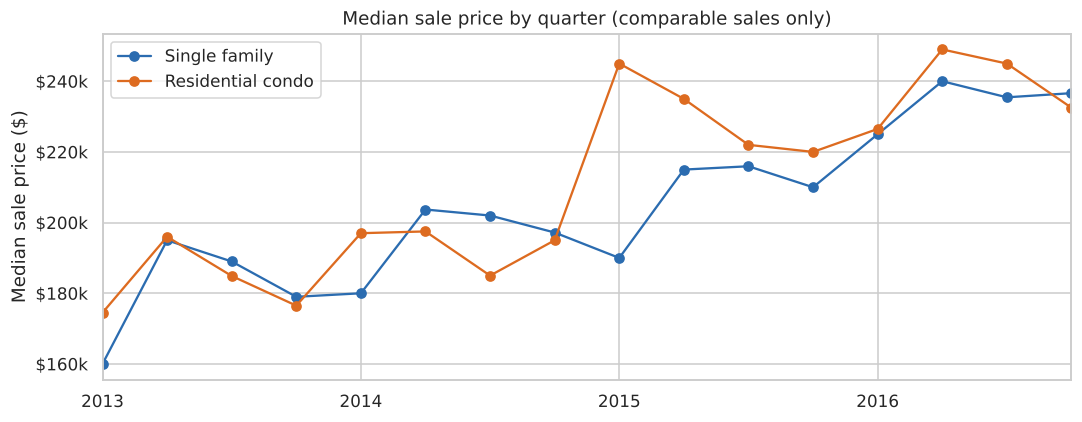

In [22]:
# Median sale price by quarter
q = comp.assign(quarter=comp["sale_date"].dt.to_period("Q").dt.to_timestamp())
trend = q.groupby(["quarter", "land_use"])["sale_price"].median().unstack()

fig, ax = plt.subplots(figsize=(10, 4))
trend["SINGLE FAMILY"].plot(ax=ax, color=BLUE, marker="o", label="Single family")
trend["RESIDENTIAL CONDO"].plot(ax=ax, color=ORANGE, marker="o", label="Residential condo")
ax.set_title("Median sale price by quarter (comparable sales only)")
ax.set_xlabel(""); ax.set_ylabel("Median sale price ($)")
ax.yaxis.set_major_formatter(lambda v, _: f"${v/1000:,.0f}k")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "03_median_price_trend.png", dpi=150, bbox_inches="tight")
plt.show()

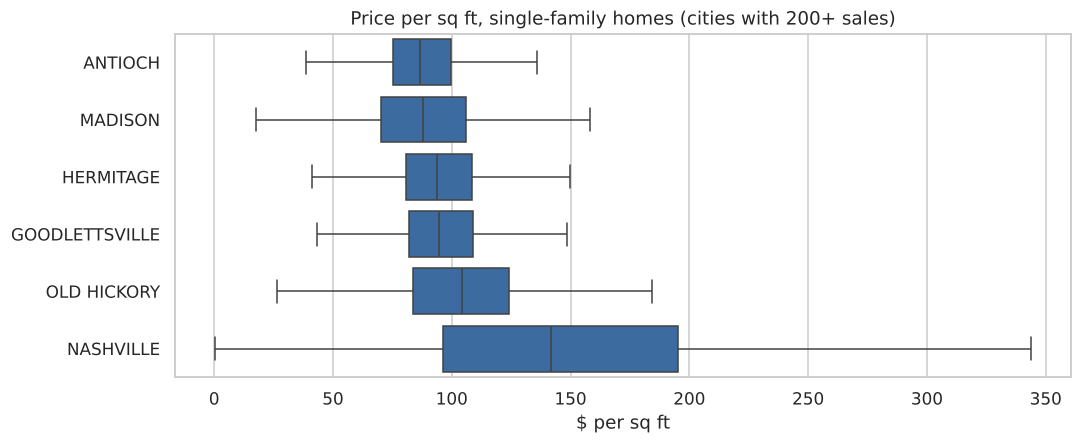

In [23]:
# Price per square foot, single-family homes with assessor data, larger cities
sf = df[(df["land_use"] == "SINGLE FAMILY") & df["price_per_sqft"].notna()]
top = sf["property_city"].value_counts().loc[lambda s: s >= 200].index
order = sf[sf["property_city"].isin(top)].groupby("property_city")["price_per_sqft"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.boxplot(data=sf[sf["property_city"].isin(top)], y="property_city", x="price_per_sqft",
            order=order, color=BLUE, showfliers=False, ax=ax)
ax.set_title("Price per sq ft, single-family homes (cities with 200+ sales)")
ax.set_xlabel("$ per sq ft"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig(IMAGES / "04_price_per_sqft_by_city.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Save outputs

In [24]:
df.to_csv("../data/processed/nashville_housing_clean.csv", index=False)
log.to_frame().to_csv("../reports/cleaning_log.csv", index=False)
log.to_frame()[["step", "rows_before", "rows_after", "cells_changed"]]

,step,rows_before,rows_after,cells_changed
0,tidy_columns,56636,56636,NaN
1,clean_text_fields,56636,56636,81243.0
2,standardise_land_use,56636,56636,1618.0
3,standardise_categoricals,56636,56636,2099.0
4,parse_types,56636,56636,NaN
5,validate_legal_reference,56636,56636,42.0
6,drop_duplicate_sales,56636,56468,NaN
7,clean_property_attributes,56468,56468,24101.0
8,add_quality_flags,56468,56468,NaN
9,add_derived_features,56468,56468,NaN


## Limitations and next steps

* The ~54% of rows without assessor data cannot be recovered from this file. Joining an external source (e.g. Metro Nashville assessor records) on `parcel_id` would fill most of them.
* `built_after_sale` and `sold_as_vacant_mismatch` rows are flagged, not corrected, because the correct value is unknown. They may be new construction or relabelled parcels.
* `price_comparable` only removes nominal and bundle prices. A fuller model would also winsorise extreme prices per neighbourhood.
* The malformed legal references that survive de-duplication are flagged (`legal_ref_valid = False`) but not repaired.